In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.datasets import fetch_california_housing

In [3]:
# Using California Housing dataset (built-in sklearn dataset)
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

In [4]:
print(f"Dataset shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Features: {list(X.columns)}")

Dataset shape: (20640, 8)
Target shape: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [5]:
# Check for missing values
print("Missing values check:")
print(f"Features: {X.isnull().sum().sum()} missing values")
print(f"Target: {y.isnull().sum()} missing values")

Missing values check:
Features: 0 missing values
Target: 0 missing values


In [6]:
# Handle missing values (if any)
if X.isnull().sum().sum() > 0:
    print("Handling missing values...")

In [8]:
# Fill numerical columns with median
numerical_cols = X.select_dtypes(include=[np.number]).columns
X[numerical_cols] = X[numerical_cols].fillna(X[numerical_cols].median())

In [9]:
# Fill categorical columns with mode
categorical_cols = X.select_dtypes(include=['object']).columns
for col in categorical_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

In [10]:
# Encode categorical variables (if any)
categorical_columns = X.select_dtypes(include=['object']).columns
if len(categorical_columns) > 0:
    print(f"Encoding categorical variables: {list(categorical_columns)}")
    le = LabelEncoder()
    for col in categorical_columns:
        X[col] = le.fit_transform(X[col])

In [11]:
# Step 3: Exploratory Data Analysis (EDA)

# Basic statistics
print("Dataset Info:")
print(f"Shape: {X.shape}")
print(f"Data types:\n{X.dtypes}")
print(f"\nTarget statistics:")
print(y.describe())

Dataset Info:
Shape: (20640, 8)
Data types:
MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
dtype: object

Target statistics:
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: target, dtype: float64


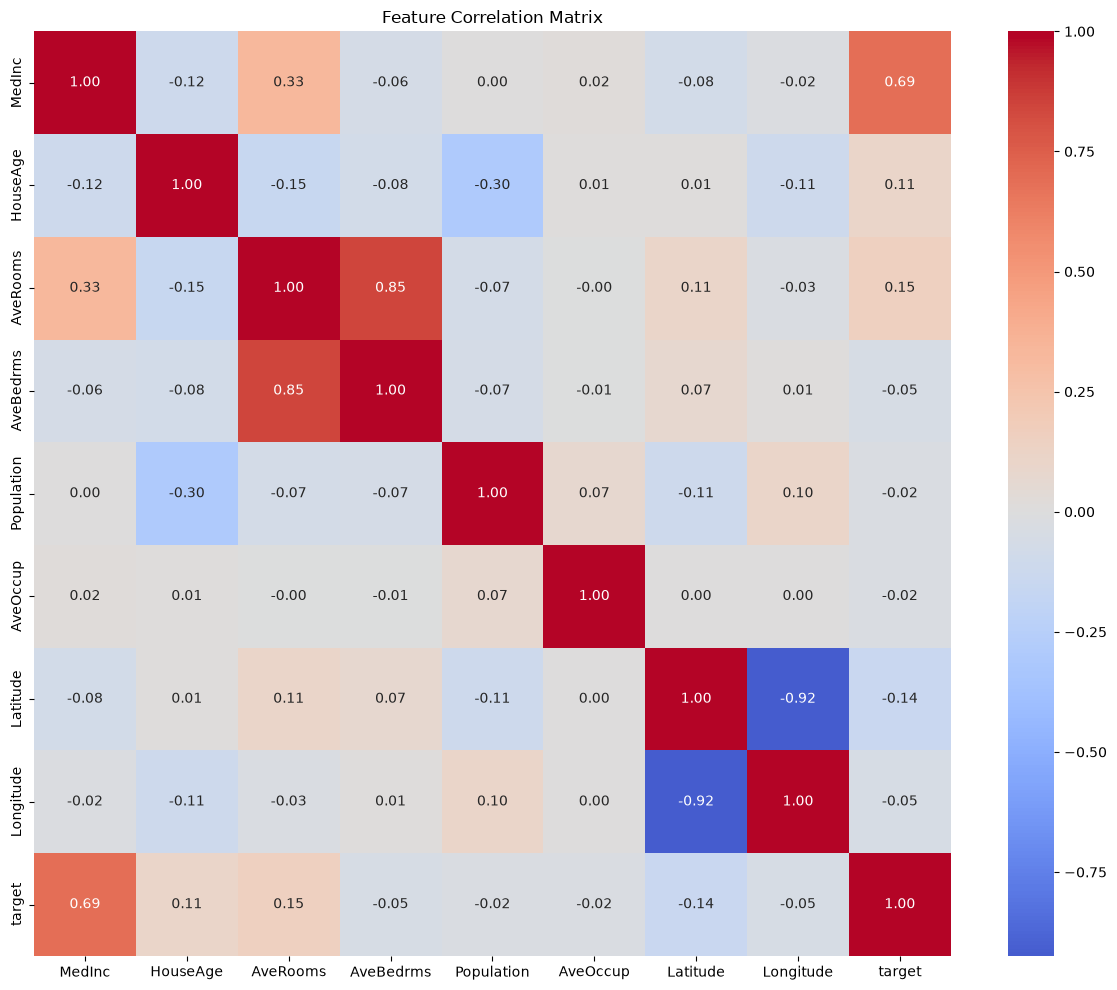

In [12]:
# Create correlation matrix
plt.figure(figsize=(12, 10))
correlation_matrix = pd.concat([X, y], axis=1).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Frequency')

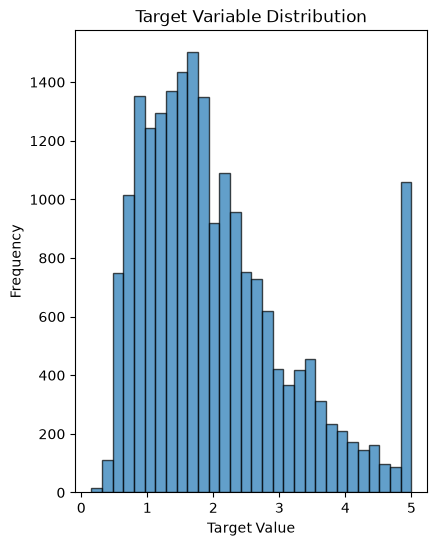

In [13]:
# Distribution of target variable
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.hist(y, bins=30, edgecolor='black', alpha=0.7)
plt.title('Target Variable Distribution')
plt.xlabel('Target Value')
plt.ylabel('Frequency')

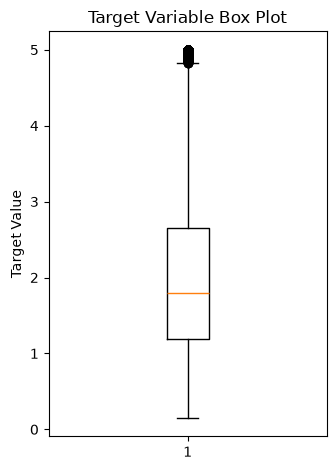

In [14]:
plt.subplot(1, 2, 2)
plt.boxplot(y)
plt.title('Target Variable Box Plot')
plt.ylabel('Target Value')
plt.tight_layout()
plt.show()

In [15]:
# Feature importance based on correlation with target
feature_importance = abs(correlation_matrix['target'].drop('target')).sort_values(ascending=False)
print(f"\nTop 5 most correlated features with target:")
for i, (feature, corr) in enumerate(feature_importance.head().items(), 1):
    print(f"{i}. {feature}: {corr:.3f}")


Top 5 most correlated features with target:
1. MedInc: 0.688
2. AveRooms: 0.152
3. Latitude: 0.144
4. HouseAge: 0.106
5. AveBedrms: 0.047


In [16]:
from sklearn.feature_selection import SelectKBest, f_regression

In [17]:
# Step 4: Transform Data
 
# Feature selection using SelectKBest
print("Performing feature selection...")
selector = SelectKBest(score_func=f_regression, k='all')
X_selected = selector.fit_transform(X, y)
feature_scores = pd.DataFrame({
    'feature': X.columns,
    'score': selector.scores_
}).sort_values('score', ascending=False)

print("Feature scores:")
print(feature_scores)

Performing feature selection...
Feature scores:
      feature         score
0      MedInc  18556.571631
2    AveRooms    487.757462
6    Latitude    438.005453
1    HouseAge    232.841479
3   AveBedrms     45.108576
7   Longitude     43.698976
4  Population     12.547410
5    AveOccup     11.635342


In [18]:
# Select top k features (let's keep all features to avoid mismatch issues)
# You can change k_best to select fewer features if needed
k_best = len(X.columns)  # Use all features to avoid feature mismatch
top_features = feature_scores.head(k_best)['feature'].tolist()
X_selected = X[top_features]
print(f"\nSelected top {k_best} features: {top_features}")


Selected top 8 features: ['MedInc', 'AveRooms', 'Latitude', 'HouseAge', 'AveBedrms', 'Longitude', 'Population', 'AveOccup']


In [19]:
# Save feature names for later use
feature_names = top_features

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
# Step 5: Split Data

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=None
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set size: 16512 samples
Testing set size: 4128 samples
Training set shape: (16512, 8)
Testing set shape: (4128, 8)


In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
# Scale/normalize features
print("\nScaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")


Scaling features...
Feature scaling completed!


In [24]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import  cross_val_score

In [25]:
# Step 6: Choose k Value

# Test different k values
k_range = range(1, 31)
k_scores = []

print("Testing different k values...")
for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='neg_mean_squared_error')
    k_scores.append(-scores.mean())

Testing different k values...


In [26]:
# Find optimal k
optimal_k = k_range[np.argmin(k_scores)]
print(f"Optimal k value: {optimal_k}")

Optimal k value: 11


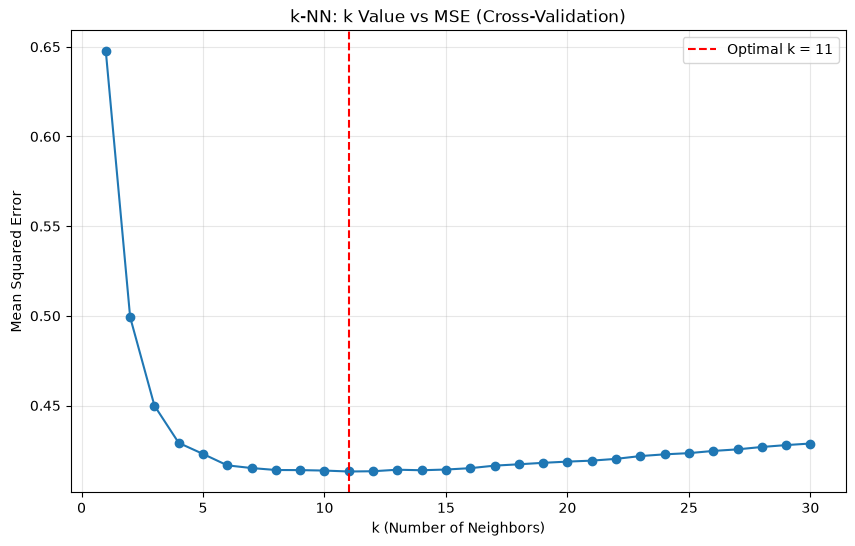

In [27]:
# Plot k vs MSE
plt.figure(figsize=(10, 6))
plt.plot(k_range, k_scores, marker='o')
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k = {optimal_k}')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Mean Squared Error')
plt.title('k-NN: k Value vs MSE (Cross-Validation)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
# Step 7: Train k-NN Regressor
# Train with optimal k
knn_model = KNeighborsRegressor(n_neighbors=optimal_k, weights='uniform', metric='euclidean')
knn_model.fit(X_train_scaled, y_train)

print(f"Model trained with k={optimal_k}")
print(f"Model parameters: {knn_model.get_params()}")

Model trained with k=11
Model parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}


In [29]:
# Step 8: Evaluate Model

# Make predictions
y_train_pred = knn_model.predict(X_train_scaled)
y_test_pred = knn_model.predict(X_test_scaled)

In [30]:
# Calculate metrics
def calculate_metrics(y_true, y_pred, dataset_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"\n{dataset_name} Metrics:")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R²:   {r2:.4f}")
    
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [32]:
train_metrics = calculate_metrics(y_train, y_train_pred, "Training")
test_metrics = calculate_metrics(y_test, y_test_pred, "Testing")


Training Metrics:
MSE:  0.3342
RMSE: 0.5781
MAE:  0.3979
R²:   0.7500

Testing Metrics:
MSE:  0.4186
RMSE: 0.6470
MAE:  0.4384
R²:   0.6806


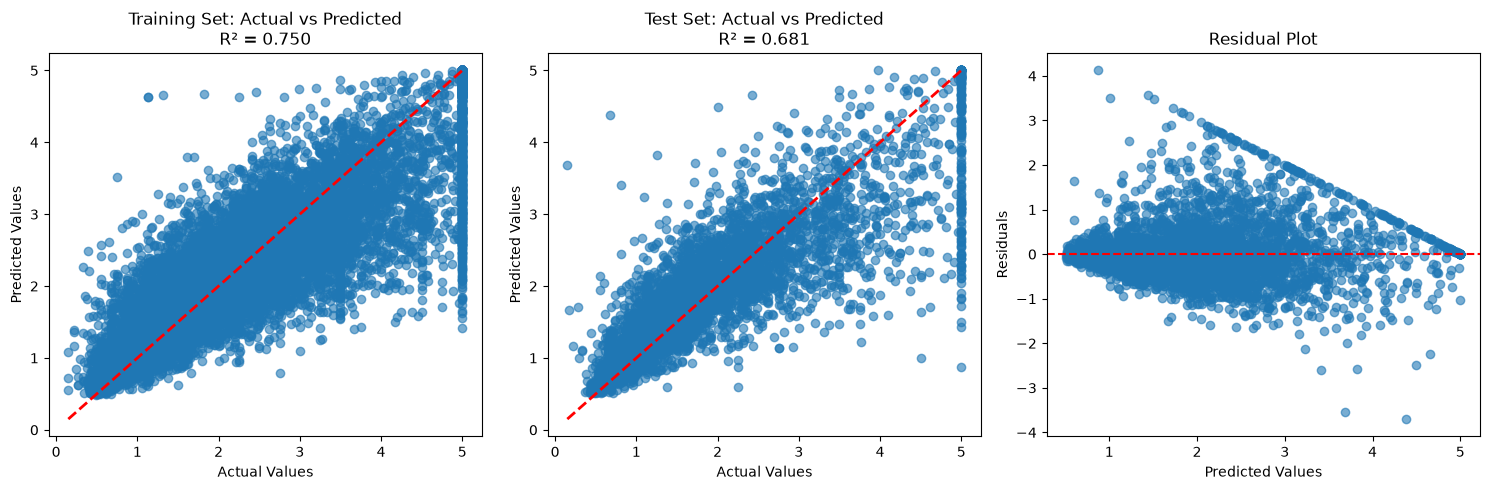

In [33]:
# Plot predictions vs actual
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(y_train, y_train_pred, alpha=0.6)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title(f'Training Set: Actual vs Predicted\nR² = {train_metrics["R2"]:.3f}')

plt.subplot(1, 3, 2)
plt.scatter(y_test, y_test_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title(f'Test Set: Actual vs Predicted\nR² = {test_metrics["R2"]:.3f}')

plt.subplot(1, 3, 3)
residuals = y_test - y_test_pred
plt.scatter(y_test_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.tight_layout()
plt.show()

In [34]:
from sklearn.model_selection import  GridSearchCV

In [35]:
# Step 9: Hyperparameter Tuning

# Define parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

print("Performing Grid Search...")
grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {-grid_search.best_score_:.4f}")

Performing Grid Search...
Fitting 5 folds for each of 42 candidates, totalling 210 fits

Best parameters: {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}
Best cross-validation score: 0.3609


In [36]:
# Train final model with best parameters
best_knn = grid_search.best_estimator_
y_test_pred_tuned = best_knn.predict(X_test_scaled)

In [37]:
# Evaluate tuned model
tuned_metrics = calculate_metrics(y_test, y_test_pred_tuned, "Tuned Model")


Tuned Model Metrics:
MSE:  0.3642
RMSE: 0.6034
MAE:  0.4058
R²:   0.7221


In [38]:
# Compare models
print("\nMODEL COMPARISON:")
print(f"Original Model R²: {test_metrics['R2']:.4f}")
print(f"Tuned Model R²:    {tuned_metrics['R2']:.4f}")
print(f"Improvement:       {tuned_metrics['R2'] - test_metrics['R2']:.4f}")


MODEL COMPARISON:
Original Model R²: 0.6806
Tuned Model R²:    0.7221
Improvement:       0.0415


In [39]:
import joblib

In [40]:
# Step 10: Save Model

# Save the trained model, scaler, and feature names
model_filename = 'knn_regressor_model.pkl'
scaler_filename = 'feature_scaler.pkl'
features_filename = 'feature_names.pkl'

joblib.dump(best_knn, model_filename)
joblib.dump(scaler, scaler_filename)
joblib.dump(feature_names, features_filename)

print(f"Model saved as: {model_filename}")
print(f"Scaler saved as: {scaler_filename}")
print(f"Feature names saved as: {features_filename}")

Model saved as: knn_regressor_model.pkl
Scaler saved as: feature_scaler.pkl
Feature names saved as: feature_names.pkl
